In [1]:
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.neighbors import KNeighborsClassifier

# Sample Flipkart product reviews
reviews = [
    "This product is very good",
    "Excellent quality and amazing product",
    "I love this product",
    "Very bad product",
    "Worst quality ever",
    "Not worth the money",
    "Amazing performance",
    "Poor quality and bad service",
    "Highly recommended",
    "Completely useless product"
]

# Review labels
labels = [
    "Positive", "Positive", "Positive",
    "Negative", "Negative", "Negative",
    "Positive", "Negative", "Positive", "Negative"
]

# Convert text into numerical features
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(reviews)

# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=3)

# Train model
knn_model.fit(X, labels)

# Test a new review
new_review = ["Excellent product and good quality"]

new_review_vector = vectorizer.transform(new_review)

prediction = knn_model.predict(new_review_vector)

print("New Review:", new_review[0])
print("Predicted Sentiment:", prediction[0])

New Review: Excellent product and good quality
Predicted Sentiment: Positive


### Task 2: Compare Euclidean and Manhattan distance for Spotify songs

In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Sample Spotify dataset
data = {
    "tempo": [130, 140, 125, 150, 135, 145, 120, 138,
              80, 90, 85, 75, 95, 88, 78, 92,
              128, 82, 142, 87],

    "danceability": [0.85, 0.90, 0.80, 0.88, 0.82,
                     0.91, 0.78, 0.86, 0.40, 0.45,
                     0.35, 0.30, 0.50, 0.42, 0.38,
                     0.48, 0.84, 0.32, 0.89, 0.44],

    "energy": [0.95, 0.90, 0.88, 0.98, 0.92,
               0.94, 0.85, 0.91, 0.30, 0.25,
               0.35, 0.20, 0.40, 0.28, 0.32,
               0.38, 0.93, 0.22, 0.96, 0.33],

    "playlist": [
        "Workout", "Workout", "Workout", "Workout",
        "Workout", "Workout", "Workout", "Workout",
        "Chill", "Chill", "Chill", "Chill",
        "Chill", "Chill", "Chill", "Chill",
        "Workout", "Chill", "Workout", "Chill"
    ]
}

df = pd.DataFrame(data)

# Features and target
X = df[["tempo", "danceability", "energy"]]
y = df["playlist"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Euclidean distance KNN
knn_euclidean = KNeighborsClassifier(
    n_neighbors=3,
    metric="euclidean"
)

knn_euclidean.fit(X_train_scaled, y_train)

pred_euclidean = knn_euclidean.predict(X_test_scaled)

accuracy_euclidean = accuracy_score(y_test, pred_euclidean)


# Manhattan distance KNN
knn_manhattan = KNeighborsClassifier(
    n_neighbors=3,
    metric="manhattan"
)

knn_manhattan.fit(X_train_scaled, y_train)

pred_manhattan = knn_manhattan.predict(X_test_scaled)

accuracy_manhattan = accuracy_score(y_test, pred_manhattan)


# Display accuracy
print("Euclidean Accuracy:", accuracy_euclidean)
print("Manhattan Accuracy:", accuracy_manhattan)

Euclidean Accuracy: 1.0
Manhattan Accuracy: 1.0


### Task 3: Gaussian Naive Bayes for IRCTC booking prediction

In [3]:
import pandas as pd

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Sample IRCTC booking dataset
data = {
    "booking_time": [
        30, 25, 20, 15, 10, 5, 2, 1, 40, 35,
        28, 18, 12, 8, 4, 3, 50, 45, 6, 9
    ],

    "train_popularity": [
        2, 3, 2, 4, 5, 5, 5, 5, 1, 2,
        3, 4, 5, 5, 5, 4, 1, 2, 5, 4
    ],

    "travel_day": [
        0, 0, 1, 0, 1, 1, 1, 0, 0, 1,
        0, 1, 0, 1, 1, 0, 0, 1, 0, 1
    ],

    "booking_status": [
        "Confirmed", "Confirmed", "Confirmed", "Confirmed",
        "Waitlisted", "Waitlisted", "Waitlisted", "Waitlisted",
        "Confirmed", "Confirmed", "Confirmed", "Confirmed",
        "Waitlisted", "Waitlisted", "Waitlisted", "Waitlisted",
        "Confirmed", "Confirmed", "Waitlisted", "Waitlisted"
    ]
}

df = pd.DataFrame(data)

# Features and target
X = df[["booking_time", "train_popularity", "travel_day"]]
y = df["booking_status"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Create Gaussian Naive Bayes model
model = GaussianNB()

# Train model
model.fit(X_train, y_train)

# Predictions
predictions = model.predict(X_test)

# Check accuracy
accuracy = accuracy_score(y_test, predictions)

print("Actual Status:")
print(list(y_test))

print("\nPredicted Status:")
print(predictions)

print("\nModel Accuracy:", accuracy)

# Predict a new booking
new_booking = pd.DataFrame({
    "booking_time": [20],
    "train_popularity": [3],
    "travel_day": [0]
})

new_prediction = model.predict(new_booking)

print("\nNew Booking Prediction:", new_prediction[0])

Actual Status:
['Confirmed', 'Confirmed', 'Waitlisted', 'Waitlisted', 'Confirmed']

Predicted Status:
['Confirmed' 'Confirmed' 'Waitlisted' 'Waitlisted' 'Confirmed']

Model Accuracy: 1.0

New Booking Prediction: Confirmed


### Task 4: Multinomial Naive Bayes for WhatsApp messages

Model Accuracy: 0.6666666666666666


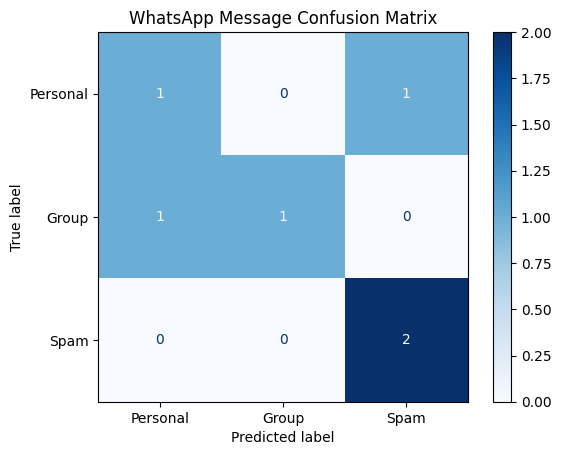


New Message Category: Spam


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Sample WhatsApp messages
messages = [
    "Hello how are you",
    "Good morning friend",
    "I will call you later",
    "Happy birthday dear",
    "Are you coming today",
    "Please send me the notes",
    "Everyone join the meeting",
    "Team meeting at 5 pm",
    "Group photo is ready",
    "Please share the assignment",
    "Congratulations you won a prize",
    "Click this link to win money",
    "Free recharge claim now",
    "You won a lottery prize",
    "Earn money from home click here",
    "Get free gift now",
    "Hello see you tomorrow",
    "Let's meet this evening",
    "Team match starts today",
    "Everyone submit the project"
]

labels = [
    "Personal", "Personal", "Personal", "Personal",
    "Personal", "Personal",
    "Group", "Group", "Group", "Group",
    "Spam", "Spam", "Spam", "Spam", "Spam", "Spam",
    "Personal", "Personal", "Group", "Group"
]

# Convert messages into numerical features
vectorizer = CountVectorizer()

X = vectorizer.fit_transform(messages)
y = labels

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Create Multinomial Naive Bayes model
model = MultinomialNB()

# Train model
model.fit(X_train, y_train)

# Predictions
predictions = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", accuracy)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    predictions,
    labels=["Personal", "Group", "Spam"]
)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Personal", "Group", "Spam"]
)

display.plot(cmap="Blues")

plt.title("WhatsApp Message Confusion Matrix")
plt.show()

# Test a new message
new_message = ["Congratulations you won free money"]

new_message_vector = vectorizer.transform(new_message)

print("\nNew Message Category:", model.predict(new_message_vector)[0])

### Task 5: KNN image classifier – Cricket Bat vs Football

Image Classification Accuracy: 1.0


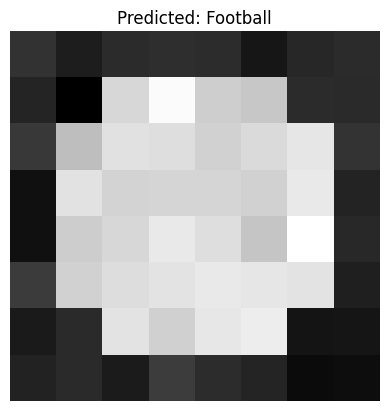

Actual Class: Football
Predicted Class: Football


In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Generate synthetic images
np.random.seed(42)

images = []
labels = []

# Generate cricket bat images
for i in range(50):

    image = np.zeros((8, 8))

    # Bat shape
    image[1:7, 3:5] = 1
    image[0:2, 2:6] = 1

    # Add small random noise
    image = image + np.random.normal(0, 0.1, (8, 8))

    images.append(image)
    labels.append("Cricket Bat")


# Generate football images
for i in range(50):

    image = np.zeros((8, 8))

    # Football-like circular pattern
    for row in range(8):
        for col in range(8):

            distance = np.sqrt((row - 3.5)**2 + (col - 3.5)**2)

            if distance < 3:
                image[row, col] = 1

    # Add small random noise
    image = image + np.random.normal(0, 0.1, (8, 8))

    images.append(image)
    labels.append("Football")


# Convert images into arrays
images = np.array(images)
labels = np.array(labels)

# Flatten images into numerical features
X = images.reshape(len(images), -1)
y = labels

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create KNN classifier
model = KNeighborsClassifier(n_neighbors=3)

# Train model
model.fit(X_train, y_train)

# Predict images
predictions = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, predictions)

print("Image Classification Accuracy:", accuracy)

# Display one test image
plt.imshow(X_test[0].reshape(8, 8), cmap="gray")
plt.title("Predicted: " + predictions[0])
plt.axis("off")
plt.show()

print("Actual Class:", y_test[0])
print("Predicted Class:", predictions[0])